In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd
from scipy import stats 

In [2]:
ns = 100  # number of samples
sd = np.random.randint(1, 101, ns)
ts = 4 * sd + np.random.normal(0, 1, ns)
df = pd.DataFrame({
    "StudyHour": sd,
    "TestScore": ts
})
print("Complete Dataset:")
print(df)

Complete Dataset:
    StudyHour   TestScore
0          82  328.652758
1          13   52.202709
2          82  330.343566
3          36  146.298560
4          41  163.590860
..        ...         ...
95         73  292.176448
96         94  374.944231
97         35  138.544891
98         53  208.749633
99         84  334.730044

[100 rows x 2 columns]


In [3]:
x=df.StudyHour
y=df.TestScore

from sklearn.model_selection import train_test_split 
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=20,random_state=42)
print("Number of training samples:", len(xtrain))
print("Number of testing samples:", len(xtest))


Number of training samples: 80
Number of testing samples: 20


In [4]:
#model creationlinear regression predictions.csv
from sklearn import linear_model
lr = linear_model.LinearRegression()
xtrain=xtrain.values.reshape(80,1)
xtest=xtest.values.reshape(20,1)
#training
lr.fit(xtrain, ytrain)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[4.]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.06118
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[238.06]


In [12]:
cf = lr.coef_[0].round(2)
intc = lr.intercept_.round(2)

print("\nSlope (Coefficient):", cf)
print("Intercept:", intc)

#Equation of the line
equ=f"TestScore={cf}*StudyHour+{intc}"
print("\nRegression Equation:", equ)


Slope (Coefficient): 4.0
Intercept: 0.06

Regression Equation: TestScore=4.0*StudyHour+0.06


In [6]:
#model testing
ypred=lr.predict(xtest)
print(ypred)
print(ytest)

[164.00415377 148.0097177    4.05979311 267.9679882  140.01249967
 303.95546935 271.96659721  96.02780049 375.93043165 327.94712345
 391.92486771   8.05840212 303.95546935  32.05005622 331.94573246
 164.00415377 271.96659721 271.96659721  96.02780049 259.97077017]
83    164.331676
53    147.836159
70      3.856084
45    268.297025
44    141.233214
39    304.347196
22    272.974342
80     96.007742
10    376.601361
0     328.652758
18    390.559183
30      8.219265
73    302.352951
33     32.488007
90    331.715916
4     163.590860
76    272.565676
77    272.308146
12     96.014687
31    259.263208
Name: TestScore, dtype: float64


In [7]:
from sklearn import metrics
RSS=np.sum((ytest-ypred)**2).round(2)
print("RSS:",RSS)
MAE=metrics.mean_absolute_error(ytest,ypred)
print("MAE:",MAE)
MSE=metrics.mean_squared_error(ytest,ypred)
print("MSE:",MSE)
RMSE=np.sqrt(MSE)
print("RMSE:",RMSE)
TSS=np.sum((ytest-np.mean(ytest))**2).round(2)
print("TSS:",TSS)
R2=(1-(RSS/TSS)).round(2)
print("R2 value:",R2)

RSS: 9.75
MAE: 0.5461032161852095
MSE: 0.48727987416688334
RMSE: 0.6980543490064963
TSS: 277754.91
R2 value: 1.0


In [8]:
df2 = pd.DataFrame({
    "StudyHour": xtest[:, 0],
    "Y-Actual": ytest.round(2),
    "Y-Predict": ypred.round(2)
})
df2 = df2.reset_index(drop=True)
print("\nActual vs Predicted:")
print(df2)


Actual vs Predicted:
    StudyHour  Y-Actual  Y-Predict
0          41    164.33     164.00
1          37    147.84     148.01
2           1      3.86       4.06
3          67    268.30     267.97
4          35    141.23     140.01
5          76    304.35     303.96
6          68    272.97     271.97
7          24     96.01      96.03
8          94    376.60     375.93
9          82    328.65     327.95
10         98    390.56     391.92
11          2      8.22       8.06
12         76    302.35     303.96
13          8     32.49      32.05
14         83    331.72     331.95
15         41    163.59     164.00
16         68    272.57     271.97
17         68    272.31     271.97
18         24     96.01      96.03
19         65    259.26     259.97


In [9]:
# Save results to CSV
df2.to_csv("linear_regression_predictions.csv", index=False)
print("\nResults saved successfully.")



Results saved successfully.


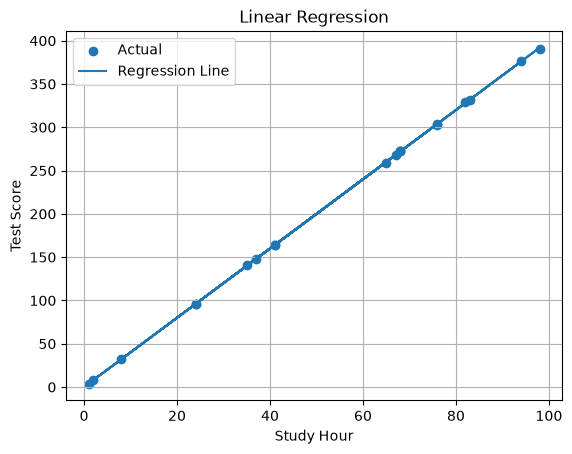

In [10]:
plt.scatter(xtest, ytest, label="Actual")
plt.plot(xtest, ypred, label="Regression Line")
plt.xlabel("Study Hour")
plt.ylabel("Test Score")
plt.title("Linear Regression")
plt.legend()
plt.grid(True)
plt.show()